# Aula 05 — Estatística Descritiva

**Aluno:** Davi Horácio de Souza · **Matrícula:** 20250059934

Neste exercício refaço o roteiro da aula 5: descrever o **valor dos pedidos** do Online Retail com medidas de tendência central, dispersão, assimetria e curtose, e discutir qual medida contar ao gerente de vendas. No final completo o "Para casa".

Esta aula abre a **Unidade 2**, e a pasta [`Unidade_02`](..) funciona como o projeto da unidade, no mesmo padrão da Unidade 1: tem o próprio ambiente, as dependências e os dados. Os comandos de terminal aparecem em blocos `bash` com a saída obtida, e o código fica em células executáveis. Cada resultado é seguido de uma análise.

## 1. Preparando o projeto da Unidade 2

```bash
cd ..
mkdir -p data
uv venv
uv pip install pandas openpyxl matplotlib seaborn scipy
uv pip freeze > requirements.txt
cat requirements.txt
```

Saída:

```text
Using CPython 3.12.13
Creating virtual environment at: .venv
Activate with: source .venv/bin/activate
Resolved 16 packages in 277ms
Downloading scipy (33.7MiB)
 Downloaded scipy
Prepared 1 package in 3.07s
Installed 16 packages in 932ms
 + contourpy==1.4.0
 + cycler==0.12.1
 + et-xmlfile==2.0.0
 + fonttools==4.68.0
 + kiwisolver==1.5.1
 + matplotlib==3.11.2
 + numpy==2.5.5
 + openpyxl==3.1.5
 + packaging==26.3
 + pandas==3.1.1
 + pillow==13.0.0
 + pyparsing==3.3.3
 + python-dateutil==4.0.0
 + scipy==1.18.1
 + seaborn==0.13.2
 + tzdata==2026.6
contourpy==1.4.0
cycler==0.12.1
et-xmlfile==2.0.0
fonttools==4.68.0
kiwisolver==1.5.1
matplotlib==3.11.2
numpy==2.5.5
openpyxl==3.1.5
packaging==26.3
pandas==3.1.1
pillow==13.0.0
pyparsing==3.3.3
python-dateutil==4.0.0
scipy==1.18.1
seaborn==0.13.2
tzdata==2026.6
```

**Análise:** a Unidade 2 ganhou o próprio ambiente virtual (`uv venv`) e as dependências da aula: além de pandas, openpyxl e matplotlib, entram o **seaborn**, para gráficos estatísticos, e o **scipy**, que traz funções prontas como média aparada, IQR, assimetria e curtose. O `requirements.txt` registra os 16 pacotes com versão fixa, então a unidade pode ser reproduzida de forma independente da Unidade 1.

```bash
curl -sSL -o data/online_retail.zip "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
unzip -o data/online_retail.zip -d data/
mv "data/Online Retail.xlsx" data/online_retail.xlsx
ls -lh data/
```

Saída:

```text
Archive:  data/online_retail.zip
 extracting: data/Online Retail.xlsx  
total 46M
-rwx------ 1 davi davi 23M May 22  2023 online_retail.xlsx
-rw-rw-r-- 1 davi davi 23M Nov 22 13:15 online_retail.zip
```

**Análise:** o Online Retail foi baixado para `Unidade_02/data/` direto da fonte oficial, com os mesmos comandos da Aula 02. São 23 MB que ficam fora do Git, porque a pasta `data/` está no `.gitignore`.

```bash
cat > README.md <<'EOF'
# Unidade 02 — Estatística

Projeto da Unidade 2 da disciplina de Ciência de Dados: estatística descritiva e inferencial aplicada ao Online Retail.

## Dados

- **Dataset:** Online Retail (UCI Machine Learning Repository)
- **Fonte:** https://archive.ics.uci.edu/dataset/352/online+retail
- **Licença:** CC BY 4.0

Para baixar, rode na pasta `Unidade_02`:

    curl -L -o data/online_retail.zip "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
    unzip -o data/online_retail.zip -d data/
    mv "data/Online Retail.xlsx" data/online_retail.xlsx
EOF
cat README.md
```

Saída:

```text
# Unidade 02 — Estatística

Projeto da Unidade 2 da disciplina de Ciência de Dados: estatística descritiva e inferencial aplicada ao Online Retail.

## Dados

- **Dataset:** Online Retail (UCI Machine Learning Repository)
- **Fonte:** https://archive.ics.uci.edu/dataset/352/online+retail
- **Licença:** CC BY 4.0

Para baixar, rode na pasta `Unidade_02`:

    curl -L -o data/online_retail.zip "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
    unzip -o data/online_retail.zip -d data/
    mv "data/Online Retail.xlsx" data/online_retail.xlsx
```

**Análise:** o README da unidade documenta a fonte, a licença e os comandos de download dos dados. Quem clonar o repositório encontra `data/` vazia, mas tem a receita para recriá-la.

```bash
printf ".venv/\n__pycache__/\ndata/\n*.env\n.ipynb_checkpoints/\n" > .gitignore
cat .gitignore
git status --short --untracked-files=all .
```

Saída:

```text
.venv/
__pycache__/
data/
*.env
.ipynb_checkpoints/
?? .gitignore
?? Aula_05/exercicio_aula05.ipynb
?? README.md
?? requirements.txt
```

**Análise:** o `.gitignore` da unidade tem as mesmas regras do da Unidade 1: deixa de fora o ambiente (`.venv/`), os arquivos gerados pelo Python e pelo Jupyter, os dados (`data/`) e os segredos (`*.env`). O `git status` confirma: o Git enxerga só os quatro arquivos que devem ser versionados (`.gitignore`, README, `requirements.txt` e o notebook), e os 46 MB de `data/` e o `.venv` ficam de fora.

## 2. Preparando os dados

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

In [2]:
caminho_dados = Path("..") / "data" / "online_retail.xlsx"

nomes_colunas = {
    "InvoiceNo": "invoice_no",
    "StockCode": "stock_code",
    "Description": "description",
    "Quantity": "quantity",
    "InvoiceDate": "invoice_date",
    "UnitPrice": "unit_price",
    "CustomerID": "customer_id",
    "Country": "country",
}

retail = pd.read_excel(caminho_dados).rename(columns=nomes_colunas)
retail["invoice_no"] = retail["invoice_no"].astype(str)
retail["customer_id"] = retail["customer_id"].astype("Int64")
retail["revenue"] = retail["quantity"] * retail["unit_price"]
retail["is_cancelled"] = retail["invoice_no"].str.startswith("C")

filtro_venda_valida = ~retail["is_cancelled"] & retail["quantity"].gt(0) & retail["unit_price"].gt(0)
vendas = retail.loc[filtro_venda_valida].copy()

pedidos = vendas.groupby("invoice_no", as_index=False).agg(
    order_date=("invoice_date", "min"),
    customer_id=("customer_id", "first"),
    country=("country", "first"),
    item_quantity=("quantity", "sum"),
    order_value=("revenue", "sum"),
)

clientes = vendas.dropna(subset=["customer_id"]).groupby("customer_id", as_index=False).agg(
    revenue=("revenue", "sum"),
    order_count=("invoice_no", "nunique"),
    country=("country", "first"),
)

print(f"Pedidos: {len(pedidos):,}")
print(f"Clientes identificados: {len(clientes):,}")

Pedidos: 19,960
Clientes identificados: 4,338


**Análise:** a preparação segue a da Aula 03: mesmo filtro de vendas válidas, uma tabela de **pedidos** (19.960, um por nota fiscal) e uma de **clientes** (4.338 identificados). A variável estudada nesta aula é o `order_value`, o valor total de cada pedido.

## 3. População e amostra

In [3]:
media_populacao = pedidos["order_value"].mean()
amostra_aleatoria = pedidos.sample(n=200, random_state=42)
amostra_enviesada = pedidos.loc[pedidos["country"].eq("United Kingdom")].sample(n=200, random_state=42)
amostra_por_pais = pedidos.groupby("country").sample(n=5, random_state=42, replace=True)

pd.Series(
    {
        "Base completa (19.960 pedidos)": media_populacao,
        "Amostra aleatória (200)": amostra_aleatoria["order_value"].mean(),
        "Amostra só do Reino Unido (200)": amostra_enviesada["order_value"].mean(),
        "5 pedidos por país (190)": amostra_por_pais["order_value"].mean(),
    },
    name="valor_medio_do_pedido",
).round(2).to_frame()

,valor_medio_do_pedido
Base completa (19.960 pedidos),534.40
Amostra aleatória (200),445.14
Amostra só do Reino Unido (200),465.36
5 pedidos por país (190),1064.50


**Análise:** considerando o ano completo como a **população**, a média verdadeira é **£ 534,40**. Uma amostra aleatória de 200 pedidos deu £ 445,14 (17% abaixo), o que mostra que mesmo uma amostra bem feita oscila em torno do valor real, ainda mais numa variável tão assimétrica. A amostra só do Reino Unido (£ 465,36) é **enviesada** por construção. Já a amostra "5 pedidos por país" **dobra a média** (£ 1.064,50): ela dá a países com poucos pedidos e tickets altos o mesmo peso do Reino Unido, que tem 90% dos pedidos. O desenho da amostra muda o resultado tanto quanto o tamanho.

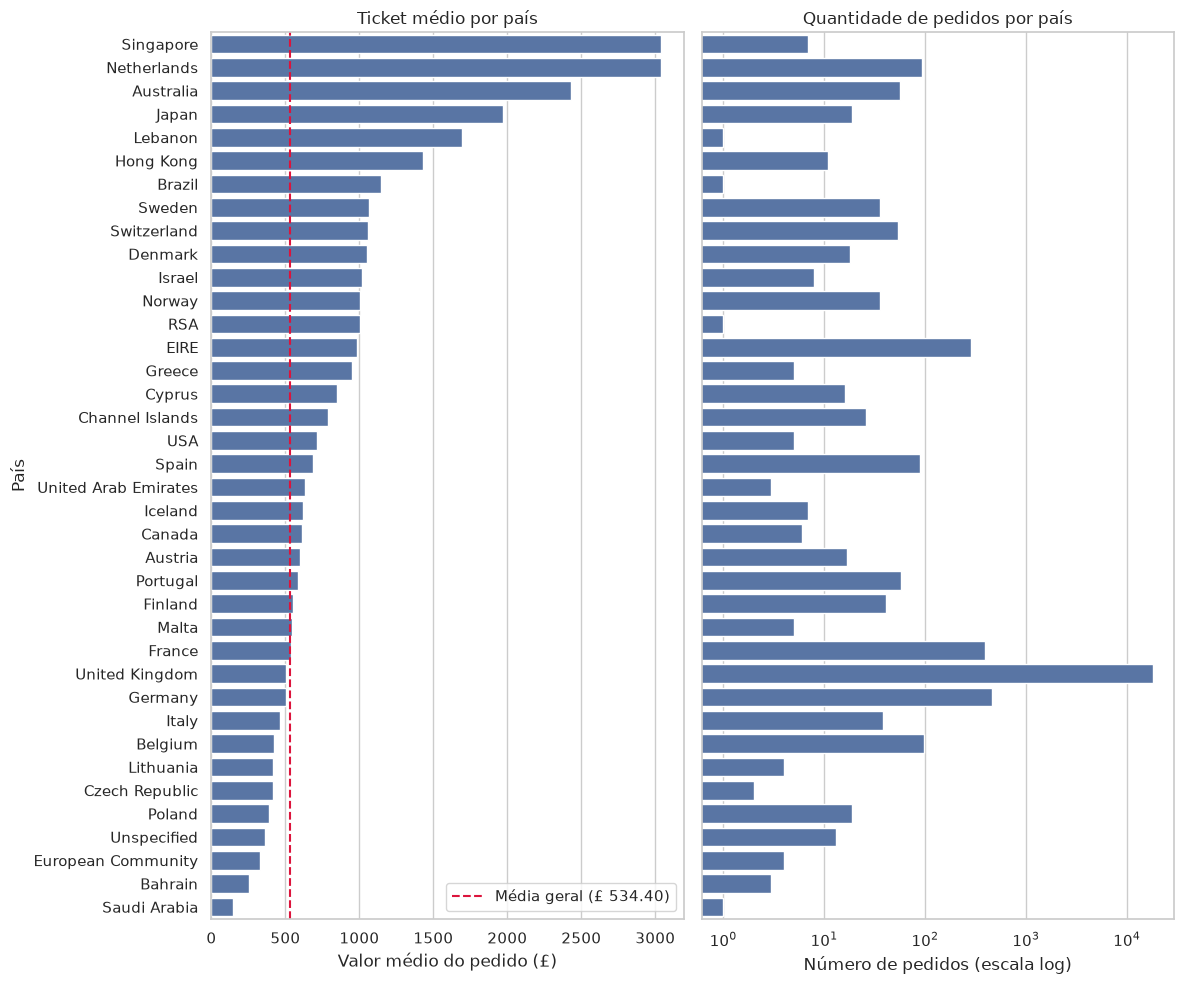

In [4]:
ticket_por_pais = pedidos.groupby("country")["order_value"].mean().sort_values(ascending=False)
pedidos_por_pais = pedidos.groupby("country").size().reindex(ticket_por_pais.index)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 10), sharey=True)
sns.barplot(x=ticket_por_pais.values, y=ticket_por_pais.index, color="C0", ax=ax1)
ax1.axvline(media_populacao, color="crimson", linestyle="--", label=f"Média geral (£ {media_populacao:.2f})")
ax1.set(xlabel="Valor médio do pedido (£)", ylabel="País", title="Ticket médio por país")
ax1.legend()
sns.barplot(x=pedidos_por_pais.values, y=pedidos_por_pais.index, color="C0", ax=ax2)
ax2.set_xscale("log")
ax2.set(xlabel="Número de pedidos (escala log)", ylabel="", title="Quantidade de pedidos por país")
fig.tight_layout()
plt.show()

**Análise:** os gráficos lado a lado explicam a amostra por país. Os maiores tickets médios (Singapura e Holanda, perto de £ 3.000, Austrália e Japão) pertencem a países com **poucos pedidos**: Singapura tem menos de 10, e Líbano, Brasil, Arábia Saudita e África do Sul (RSA) têm um só. Já o Reino Unido, com quase 20 mil pedidos, fica **abaixo da média geral**. Um ticket médio calculado sobre poucos pedidos é instável e reflete compradores atacadistas específicos, não o mercado.

## 4. Medidas de tendência central

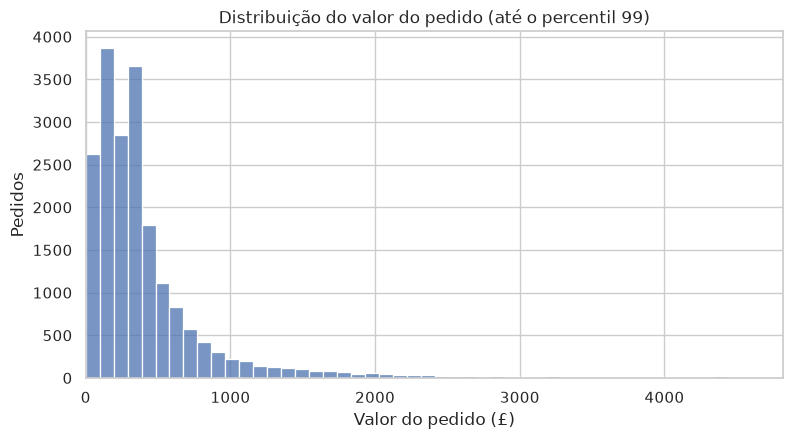

In [5]:
limite_p99 = pedidos["order_value"].quantile(0.99)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(pedidos["order_value"], bins=50, binrange=(0, limite_p99), ax=ax)
ax.set(xlim=(0, limite_p99), xlabel="Valor do pedido (£)", ylabel="Pedidos",
       title="Distribuição do valor do pedido (até o percentil 99)")
plt.show()

**Análise:** a distribuição é fortemente **assimétrica à direita**: a maior parte dos pedidos está abaixo de £ 500, com uma cauda que se estende até o percentil 99 (£ 4.821). O gráfico já corta o 1% mais alto, senão os pedidos de £ 168 mil esmagariam todas as barras perto do zero. É nesse tipo de distribuição que média e mediana mais se afastam.

### 4.1 Média

In [6]:
media_manual = pedidos["order_value"].sum() / len(pedidos)
print(f"Média manual: £ {media_manual:.2f}")
print(f"Média pandas: £ {pedidos['order_value'].mean():.2f}")

Média manual: £ 534.40
Média pandas: £ 534.40


**Análise:** a média calculada à mão (soma ÷ número de pedidos) bate com a do pandas: **£ 534,40**. A fórmula é simples, e justamente por somar todos os valores, cada pedido gigante pesa na média na proporção do seu tamanho.

### 4.2 Valor esperado

In [7]:
faixas = pd.qcut(pedidos["order_value"], q=10)
por_faixa = pedidos.groupby(faixas, observed=True)["order_value"].agg(media_da_faixa="mean", pedidos="size")
por_faixa["proporcao"] = por_faixa["pedidos"] / len(pedidos)

valor_esperado = (por_faixa["media_da_faixa"] * por_faixa["proporcao"]).sum()
print(f"E[X] pelas faixas: £ {valor_esperado:.2f} | média direta: £ {media_populacao:.2f}")
por_faixa.round(2)

E[X] pelas faixas: £ 534.40 | média direta: £ 534.40


,media_da_faixa,pedidos,proporcao
order_value,,,
"(0.379, 69.354]",27.64,1996,0.1
"(69.354, 127.5]",103.18,1998,0.1
"(127.5, 178.807]",152.85,1994,0.1
"(178.807, 239.0]",207.43,1998,0.1
"(239.0, 303.835]",274.44,1994,0.1
"(303.835, 348.564]",321.70,1996,0.1
"(348.564, 432.0]",387.31,1997,0.1
"(432.0, 585.874]",500.07,1995,0.1
"(585.874, 940.887]",727.89,1996,0.1


**Análise:** dividindo os pedidos em 10 faixas de mesmo tamanho (decis), o valor esperado (média de cada faixa × proporção) reproduz exatamente a média, £ 534,40. A tabela mostra de onde vem esse número: o último decil tem média de **£ 2.641,70**, quase 5 vezes a média geral, e sozinho responde por **49% do valor esperado**. Ou seja, metade da "média" vem de 10% dos pedidos.

### 4.3 Média ponderada e média aparada

In [8]:
media_simples_preco = vendas["unit_price"].mean()
media_ponderada_preco = (vendas["unit_price"] * vendas["quantity"]).sum() / vendas["quantity"].sum()
media_aparada = stats.trim_mean(pedidos["order_value"], proportiontocut=0.05)

print(f"Preço unitário, média simples: £ {media_simples_preco:.2f}")
print(f"Preço unitário, média ponderada pela quantidade: £ {media_ponderada_preco:.2f}")
print(f"Valor do pedido, média aparada (5% em cada ponta): £ {media_aparada:.2f}")
print(f"Valor do pedido, média simples: £ {media_populacao:.2f}")

Preço unitário, média simples: £ 3.91
Preço unitário, média ponderada pela quantidade: £ 1.91
Valor do pedido, média aparada (5% em cada ponta): £ 366.44
Valor do pedido, média simples: £ 534.40


**Análise:** no preço unitário, a média simples (£ 3,91) trata cada linha igual, mas a **média ponderada pela quantidade (£ 1,91)** mostra o preço da unidade típica vendida: os itens baratos saem em quantidades muito maiores. No valor do pedido, a **média aparada** (tirando 5% de cada ponta) cai para **£ 366,44**, 31% abaixo da média simples e bem mais perto da mediana. Cortar só os extremos já muda bastante o retrato.

### 4.4 Mediana

In [9]:
mediana = pedidos["order_value"].median()
print(f"Mediana do valor do pedido: £ {mediana:.2f}")

Mediana do valor do pedido: £ 303.84


**Análise:** a mediana é **£ 303,84**: metade dos pedidos vale menos que isso, e metade vale mais. Ela depende só da posição do valor central, e não do tamanho dos extremos, por isso fica longe da média (£ 534,40) numa distribuição tão assimétrica.

### 4.5 Moda

In [10]:
print("Moda da quantidade por linha:", vendas["quantity"].mode().tolist())
print("Moda do país:", vendas["country"].mode().tolist())
print("Moda do valor do pedido: £", pedidos["order_value"].mode().round(2).tolist())

Moda da quantidade por linha: [1]
Moda do país: ['United Kingdom']
Moda do valor do pedido: £ [15.0]


**Análise:** a moda é a medida natural para variáveis categóricas e discretas: a quantidade mais comum por linha é **1 unidade** e o país mais comum é o **Reino Unido**. No valor do pedido, que é contínuo, a moda (£ 15,00) é só o valor exato que mais se repete, provavelmente um pedido pequeno e padronizado, e pouco diz sobre o pedido típico. Em variáveis contínuas, a moda é instável.

#### Distribuição bimodal: varejo e atacado (exemplo ilustrativo)

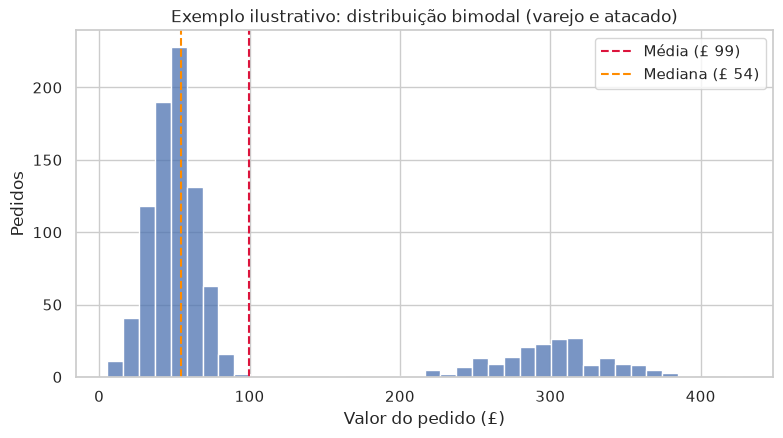

In [11]:
rng = np.random.default_rng(42)
varejo = rng.normal(loc=50, scale=15, size=800)
atacado = rng.normal(loc=300, scale=40, size=200)
pedidos_ilustrativos = np.concatenate([varejo, atacado])
pedidos_ilustrativos = pedidos_ilustrativos[pedidos_ilustrativos > 0]

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(pedidos_ilustrativos, bins=40, ax=ax)
ax.axvline(pedidos_ilustrativos.mean(), color="crimson", linestyle="--", label=f"Média (£ {pedidos_ilustrativos.mean():.0f})")
ax.axvline(np.median(pedidos_ilustrativos), color="darkorange", linestyle="--", label=f"Mediana (£ {np.median(pedidos_ilustrativos):.0f})")
ax.set(xlabel="Valor do pedido (£)", ylabel="Pedidos", title="Exemplo ilustrativo: distribuição bimodal (varejo e atacado)")
ax.legend()
plt.show()

**Análise:** no exemplo ilustrativo, com 800 pedidos de varejo (em torno de £ 50) e 200 de atacado (em torno de £ 300), a distribuição tem **dois picos**. A média (**£ 99**) cai **no vazio entre os dois grupos**, num valor que praticamente nenhum pedido tem, e a mediana (£ 54) descreve só o varejo, que é a maioria. Quando há grupos diferentes misturados, nenhuma medida única resume bem os dados: o certo é separar os grupos e descrever cada um.

### 4.6 Média versus mediana: o problema do cliente atacadista

In [12]:
maior_cliente = clientes.nlargest(1, "revenue")
clientes_sem_maior = clientes.loc[clientes["customer_id"].ne(maior_cliente["customer_id"].iloc[0])]

print(f"Maior cliente: {maior_cliente['customer_id'].iloc[0]} ({maior_cliente['country'].iloc[0]}), £ {maior_cliente['revenue'].iloc[0]:,.2f}")
pd.DataFrame(
    {
        "com todos": [clientes["revenue"].mean(), clientes["revenue"].median()],
        "sem o maior cliente": [clientes_sem_maior["revenue"].mean(), clientes_sem_maior["revenue"].median()],
    },
    index=["média", "mediana"],
).round(2)

Maior cliente: 14646 (Netherlands), £ 280,206.02


,com todos,sem o maior cliente
média,2054.27,1990.13
mediana,674.48,674.45


**Análise:** o maior cliente (14646, da Holanda) comprou **£ 280.206,02**. Tirar apenas ele da base derruba a **média** de receita por cliente em £ 64 (de £ 2.054,27 para £ 1.990,13), mas a **mediana** muda só 3 centavos (de £ 674,48 para £ 674,45). É a demonstração mais direta da robustez da mediana: um único valor extremo move a média e quase não afeta a mediana.

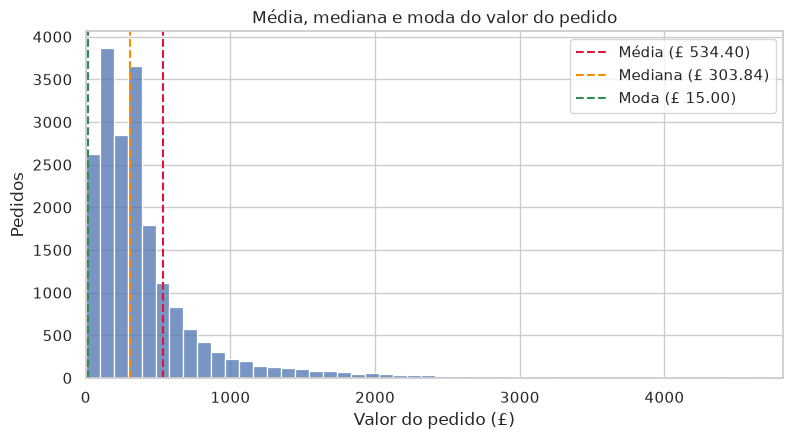

In [13]:
moda_pedido = pedidos["order_value"].mode().iloc[0]

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(pedidos["order_value"], bins=50, binrange=(0, limite_p99), ax=ax)
ax.axvline(media_populacao, color="crimson", linestyle="--", label=f"Média (£ {media_populacao:.2f})")
ax.axvline(mediana, color="darkorange", linestyle="--", label=f"Mediana (£ {mediana:.2f})")
ax.axvline(moda_pedido, color="seagreen", linestyle="--", label=f"Moda (£ {moda_pedido:.2f})")
ax.set(xlim=(0, limite_p99), xlabel="Valor do pedido (£)", ylabel="Pedidos", title="Média, mediana e moda do valor do pedido")
ax.legend()
plt.show()

**Análise:** as três medidas aparecem na ordem típica de uma distribuição assimétrica à direita: **moda (£ 15) < mediana (£ 303,84) < média (£ 534,40)**. A cauda longa puxa a média para a direita, a mediana fica no meio da massa de pedidos e a moda marca um valor pequeno e frequente.

## 5. Medidas de dispersão

### 5.1 Desvio, variância e desvio-padrão

In [14]:
valores = pedidos["order_value"]
desvios = valores - valores.mean()
variancia_manual = (desvios**2).mean()

print(f"Variância manual: {variancia_manual:,.2f} | pandas (ddof=0): {valores.var(ddof=0):,.2f}")
print(f"Desvio-padrão manual: {np.sqrt(variancia_manual):,.2f} | pandas (ddof=0): {valores.std(ddof=0):,.2f}")

Variância manual: 3,169,977.44 | pandas (ddof=0): 3,169,977.44
Desvio-padrão manual: 1,780.44 | pandas (ddof=0): 1,780.44


**Análise:** a variância (média dos desvios ao quadrado) é **3,17 milhões**, em libras ao quadrado, uma unidade difícil de interpretar. Por isso usamos o desvio-padrão, que volta para libras: **£ 1.780,44**, mais de 3 vezes a própria média. Uso `ddof=0` como no roteiro, tratando o ano como população. O padrão do pandas (`ddof=1`) seria a versão amostral.

### 5.2 Desvio absoluto médio e desvio absoluto mediano

In [15]:
desvio_absoluto_medio = desvios.abs().mean()
desvio_absoluto_mediano = stats.median_abs_deviation(valores)

print(f"Desvio-padrão: £ {valores.std(ddof=0):,.2f}")
print(f"Desvio absoluto médio: £ {desvio_absoluto_medio:,.2f}")
print(f"Desvio absoluto mediano (MAD): £ {desvio_absoluto_mediano:,.2f}")

Desvio-padrão: £ 1,780.44
Desvio absoluto médio: £ 461.42
Desvio absoluto mediano (MAD): £ 161.84


**Análise:** as três medidas de dispersão contam histórias muito diferentes. O **desvio-padrão (£ 1.780)** eleva os desvios ao quadrado, então os pedidos gigantes pesam enormemente. O **desvio absoluto médio (£ 461)** usa o valor absoluto e já é bem menor. O **desvio absoluto mediano, MAD (£ 162)**, é robusto: um pedido típico se afasta cerca de £ 162 da mediana. Para descrever a variação "normal" dos pedidos, o MAD é o mais fiel.

### 5.3 Percentis e amplitude interquartílica

In [16]:
q1, q2, q3 = valores.quantile([0.25, 0.50, 0.75])
iqr = stats.iqr(valores)
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
filtro_outlier = valores.lt(limite_inferior) | valores.gt(limite_superior)

print(f"Q1 = £ {q1:.2f} | Q2 = £ {q2:.2f} | Q3 = £ {q3:.2f} | IQR = £ {iqr:.2f}")
print(f"Limites: £ {limite_inferior:.2f} a £ {limite_superior:.2f}")
print(f"Pedidos fora dos limites: {filtro_outlier.sum():,} de {len(valores):,} ({filtro_outlier.mean():.1%})")

Q1 = £ 152.51 | Q2 = £ 303.84 | Q3 = £ 495.62 | IQR = £ 343.11
Limites: £ -362.15 a £ 1010.27
Pedidos fora dos limites: 1,811 de 19,960 (9.1%)


**Análise:** os quartis dividem os pedidos em quatro partes: Q1 = £ 152,51, mediana = £ 303,84 e Q3 = £ 495,62, com **IQR de £ 343,11** (a faixa dos 50% centrais). Pela regra de 1,5 × IQR, o limite inferior é negativo (−£ 362), então nenhum pedido é marcado por baixo. Ficam marcados **1.811 pedidos (9,1%) acima de £ 1.010,27**. A regra serve para triagem: ela aponta os pedidos que fogem do padrão, mas não diz se são erros.

In [17]:
pedidos.loc[filtro_outlier, "country"].value_counts().head(10)

country
United Kingdom    1464
EIRE                68
Germany             47
France              44
Netherlands         43
Spain               20
Switzerland         12
Norway              11
Japan               11
Australia           11
Name: count, dtype: int64

**Análise:** o Reino Unido tem a maioria dos pedidos marcados (1.464, 81%), mas proporcionalmente quem se destaca são os estrangeiros. Só **8% dos pedidos britânicos** passam do limite, contra **24% dos da Irlanda (EIRE)** e **46% dos da Holanda**. Os clientes internacionais compram em lotes maiores, típico de atacadistas que importam. Esses "outliers" são, em boa parte, os melhores clientes, e não erros.

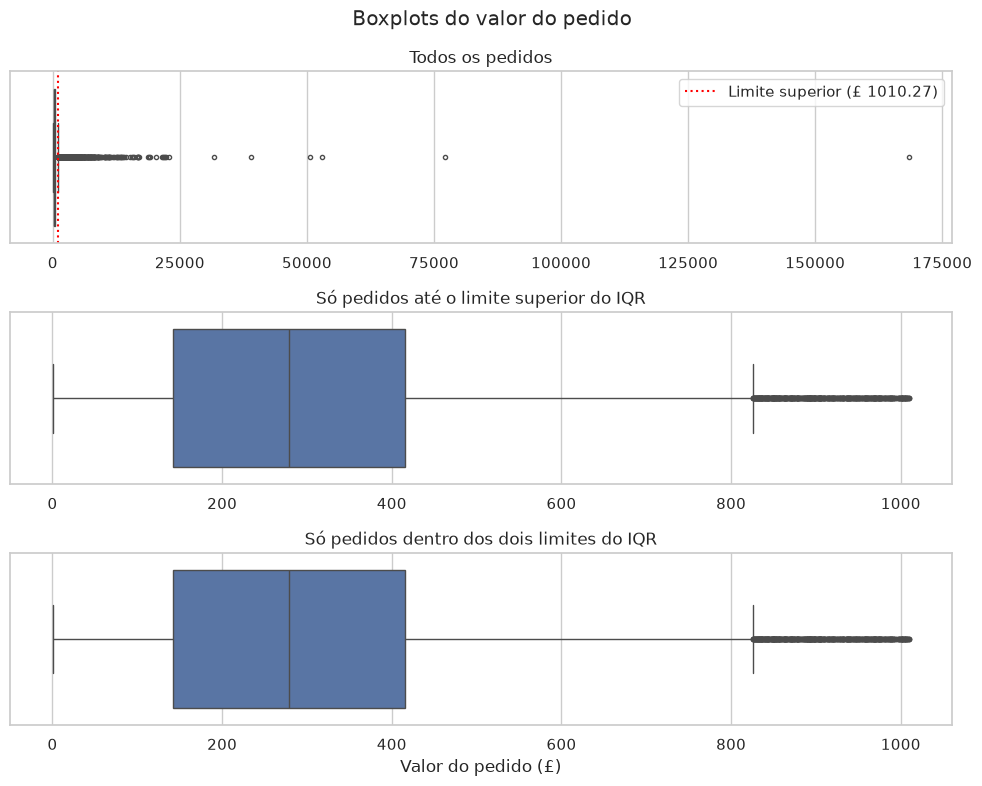

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8))
sns.boxplot(x=valores, ax=axes[0], whis=1.5, fliersize=3)
axes[0].axvline(limite_superior, color="red", linestyle=":", label=f"Limite superior (£ {limite_superior:.2f})")
axes[0].set(xlabel="", title="Todos os pedidos")
axes[0].legend()
sns.boxplot(x=valores[valores.le(limite_superior)], ax=axes[1], whis=1.5, fliersize=3)
axes[1].set(xlabel="", title="Só pedidos até o limite superior do IQR")
sns.boxplot(x=valores[valores.between(limite_inferior, limite_superior)], ax=axes[2], whis=1.5, fliersize=3)
axes[2].set(xlabel="Valor do pedido (£)", title="Só pedidos dentro dos dois limites do IQR")
fig.suptitle("Boxplots do valor do pedido")
fig.tight_layout()
plt.show()

**Análise:** no boxplot com todos os pedidos, a caixa fica espremida perto do zero, e os pontos se espalham até £ 168 mil. Ao cortar a base no limite superior (painéis 2 e 3), **surgem novos outliers acima de ~£ 830**. Isso acontece porque o boxplot recalcula os quartis sobre os dados que sobraram: a regra do IQR é relativa ao conjunto, então cortar a cauda não "acaba" com os outliers, só cria uma nova fronteira. Os painéis 2 e 3 são iguais porque não existe pedido abaixo do limite inferior, que é negativo.

In [19]:
pd.Series(
    {
        "Média": media_populacao,
        "Mediana (Q2)": q2,
        "Moda": moda_pedido,
        "Q1": q1,
        "Q3": q3,
        "Máximo": valores.max(),
        "Limite inferior (IQR)": limite_inferior,
        "Limite superior (IQR)": limite_superior,
    },
    name="valor_do_pedido",
).round(2).to_frame()

,valor_do_pedido
Média,534.40
Mediana (Q2),303.84
Moda,15.00
Q1,152.51
Q3,495.62
Máximo,168469.60
Limite inferior (IQR),-362.15
Limite superior (IQR),1010.27


**Análise:** a tabela junta as medidas principais. O que mais chama atenção é que a **média (£ 534,40) é maior que o Q3 (£ 495,62)**: mais de 75% dos pedidos valem menos que a média. Já o máximo (£ 168.469,60) está mais de 160 vezes acima do limite superior do IQR.

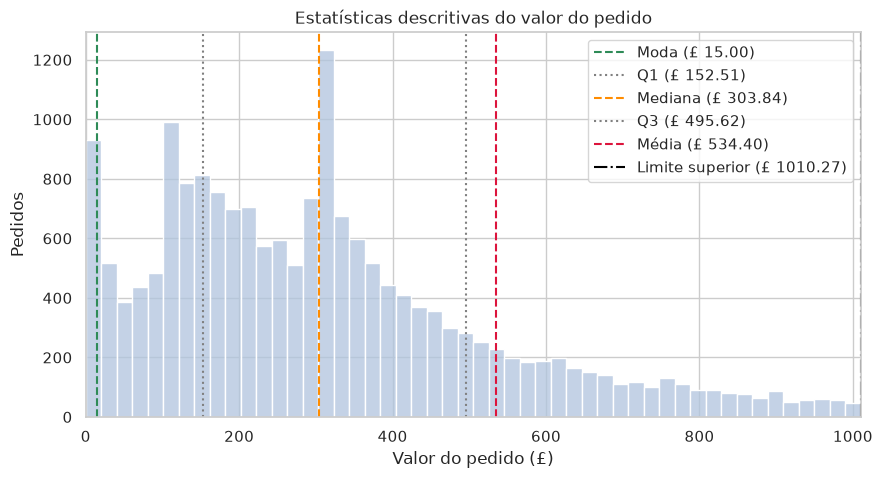

In [20]:
dentro_dos_limites = valores[valores.le(limite_superior)]

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(dentro_dos_limites, bins=50, binrange=(0, limite_superior), ax=ax, color="lightsteelblue")
for valor, cor, estilo, rotulo in [
    (moda_pedido, "seagreen", "--", "Moda"),
    (q1, "grey", ":", "Q1"),
    (mediana, "darkorange", "--", "Mediana"),
    (q3, "grey", ":", "Q3"),
    (media_populacao, "crimson", "--", "Média"),
    (limite_superior, "black", "-.", "Limite superior"),
]:
    ax.axvline(valor, color=cor, linestyle=estilo, label=f"{rotulo} (£ {valor:.2f})")
ax.set(xlim=(0, limite_superior), xlabel="Valor do pedido (£)", ylabel="Pedidos", title="Estatísticas descritivas do valor do pedido")
ax.legend()
plt.show()

**Análise:** com o histograma limitado à faixa sem outliers, dá para ver todas as medidas no lugar: a moda colada no zero, Q1, mediana e Q3 no meio da massa e a média já à direita do Q3. Aparecem picos em torno de £ 100 e de £ 300, possivelmente valores de pedido recorrentes de clientes habituais. Também fica claro que a "média" não representa um pedido comum.

## 6. Assimetria e curtose

In [21]:
desvio_padrao = valores.std(ddof=0)
assimetria_manual = (desvios**3).mean() / desvio_padrao**3
curtose_manual = (desvios**4).mean() / desvio_padrao**4 - 3

print(f"Assimetria: manual {assimetria_manual:.2f} | scipy {stats.skew(valores):.2f}")
print(f"Curtose (excesso): manual {curtose_manual:.2f} | scipy {stats.kurtosis(valores):.2f}")

Assimetria: manual 51.07 | scipy 51.07
Curtose (excesso): manual 4234.71 | scipy 4234.71


**Análise:** a **assimetria é 51,07** (uma distribuição simétrica tem 0, e valores acima de 1 já indicam forte assimetria) e a **curtose em excesso é 4.234,71** (a normal tem 0). Os dois números são extremos e confirmam uma cauda direita longuíssima, causada pelos pedidos gigantes. O cálculo manual (média dos desvios ao cubo e à quarta potência, padronizados) bate exatamente com o do scipy.

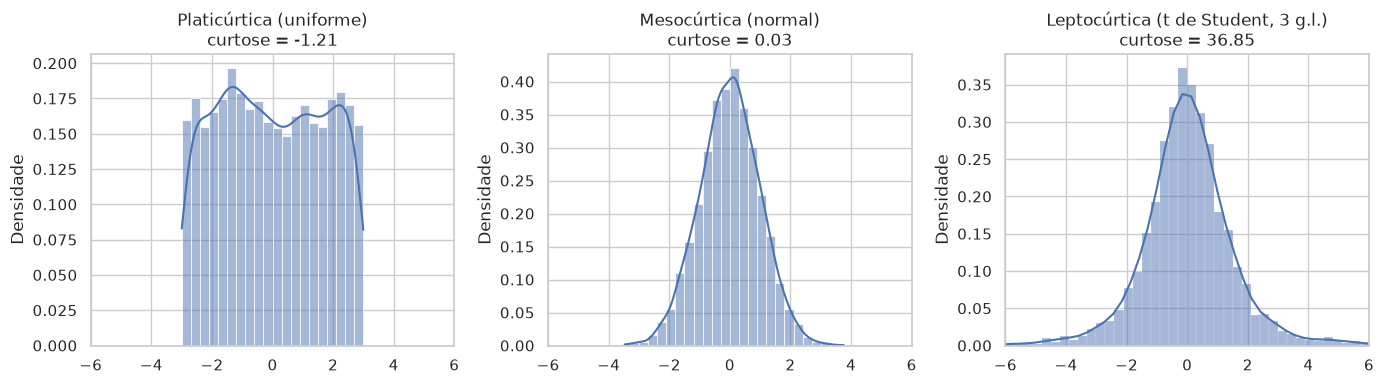

In [22]:
rng = np.random.default_rng(7)
distribuicoes = {
    "Platicúrtica (uniforme)": rng.uniform(low=-3, high=3, size=5000),
    "Mesocúrtica (normal)": rng.normal(loc=0, scale=1, size=5000),
    "Leptocúrtica (t de Student, 3 g.l.)": rng.standard_t(df=3, size=5000),
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nome, dados) in zip(axes, distribuicoes.items()):
    sns.histplot(dados, bins=40, stat="density", kde=True, ax=ax, binrange=(-6, 6))
    ax.set(xlim=(-6, 6), ylabel="Densidade", title=f"{nome}\ncurtose = {stats.kurtosis(dados):.2f}")
fig.tight_layout()
plt.show()

**Análise:** os três exemplos mostram o que a curtose mede: o peso das caudas. A **uniforme** tem curtose −1,21 (platicúrtica: sem caudas, valor teórico −1,2), a **normal** fica em 0,03 (mesocúrtica, teórico 0), e a **t de Student com 3 graus de liberdade** chega a 36,85 (leptocúrtica: caudas pesadas, com valores extremos mais frequentes). Para a t com 3 graus de liberdade, a curtose teórica nem é finita, por isso a estimativa na amostra é alta e instável. Os pedidos do Online Retail (4.234) têm caudas muito mais pesadas que qualquer um dos três exemplos.

## 7. Para casa

### 7.1 O preço unitário é tão assimétrico quanto o valor do pedido?

In [23]:
def medidas(serie):
    return pd.Series(
        {
            "média": serie.mean(),
            "mediana": serie.median(),
            "média aparada (5%)": stats.trim_mean(serie, 0.05),
            "desvio-padrão": serie.std(ddof=0),
            "MAD": stats.median_abs_deviation(serie),
            "assimetria": stats.skew(serie),
            "curtose (excesso)": stats.kurtosis(serie),
            "média / mediana": serie.mean() / serie.median(),
        }
    )


pd.DataFrame({"unit_price": medidas(vendas["unit_price"]), "order_value": medidas(pedidos["order_value"])}).round(2)

,unit_price,order_value
média,3.91,534.40
mediana,2.08,303.84
média aparada (5%),2.81,366.44
desvio-padrão,35.92,1780.44
MAD,1.23,161.84
assimetria,206.09,51.07
curtose (excesso),62482.55,4234.71
média / mediana,1.88,1.76


**Análise:** pelas medidas de forma, sim: o preço unitário é **ainda mais assimétrico** que o valor do pedido, com assimetria de **206** (4 vezes maior) e curtose de **62.483**. A razão média/mediana é parecida nas duas variáveis (1,88 e 1,76). A diferença está nos extremos: enquanto a maioria dos preços é baixa (mediana de £ 2,08, MAD de £ 1,23), poucos preços altíssimos dominam as medidas de forma. A próxima célula mostra quem são.

In [24]:
vendas.nlargest(8, "unit_price")[["invoice_no", "stock_code", "description", "quantity", "unit_price", "customer_id"]]

,invoice_no,stock_code,description,quantity,unit_price,customer_id
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,<NA>
299982,A563185,B,Adjust bad debt,1,11062.06,<NA>
173382,551697,POST,POSTAGE,1,8142.75,16029
297723,562955,DOT,DOTCOM POSTAGE,1,4505.17,<NA>
268028,560373,M,Manual,1,4287.63,<NA>
422351,573077,M,Manual,1,4161.06,12536
422376,573080,M,Manual,1,4161.06,12536
406406,571751,M,Manual,1,3949.32,12744


**Análise:** os 8 maiores "preços unitários" **não são produtos**: taxa da Amazon (£ 13.541), ajuste de dívida (£ 11.062), frete (`POSTAGE`, `DOTCOM POSTAGE`) e lançamentos manuais. Vale notar que o ajuste de dívida vem numa nota com prefixo **`A`**, que o filtro do roteiro não pega, porque ele só exclui o prefixo `C`. A assimetria extrema do preço vem desses lançamentos, e não de mercadorias caras, o que reforça os critérios de base limpa definidos na Aula 03.

### 7.2 Média ou mediana? Um parágrafo para o gerente de vendas

> **Para o gerente de vendas:** quando falamos de "pedido médio", há dois números possíveis. A **média** (£ 534) é o total vendido dividido pelo número de pedidos. Ela é a certa para **projetar faturamento**: com 2.000 pedidos num mês, dá para esperar algo perto de £ 1 milhão. Mas ela é inflada por poucos pedidos enormes de atacadistas, e por isso **três em cada quatro pedidos ficam abaixo dela**. A **mediana** (£ 304) é o valor do meio: metade dos pedidos vale menos e metade vale mais. Ela é a certa para **descrever o pedido de um cliente comum**, definir metas por vendedor, valor mínimo para frete grátis ou faixas de desconto. Na prática: use a média para planejar receita e a mediana para pensar no cliente típico, e desconfie de qualquer "média" apresentada sozinha.

### 7.3 Quantos clientes do topo é preciso tirar até média e mediana convergirem?

In [25]:
receitas = np.sort(clientes["revenue"].to_numpy())[::-1]
n = len(receitas)

curva = pd.DataFrame(
    [(k, receitas[k:].mean(), np.median(receitas[k:])) for k in range(0, n - 1)],
    columns=["removidos", "media", "mediana"],
)
curva["razao"] = curva["media"] / curva["mediana"]

for limite in [2.0, 1.5, 1.2, 1.1]:
    k = curva.loc[curva["razao"].le(limite), "removidos"].iloc[0]
    print(f"Média até {limite:.1f}x a mediana: remover {k:,} clientes ({k / n:.1%} da base)")

curva.loc[[0, 1, 10, 100, 500, 1000]].round(2)

Média até 2.0x a mediana: remover 73 clientes (1.7% da base)
Média até 1.5x a mediana: remover 441 clientes (10.2% da base)
Média até 1.2x a mediana: remover 1,448 clientes (33.4% da base)
Média até 1.1x a mediana: remover 1,931 clientes (44.5% da base)


,removidos,media,mediana,razao
0,0,2054.27,674.48,3.05
1,1,1990.13,674.45,2.95
10,10,1703.59,671.73,2.54
100,100,1250.38,653.36,1.91
500,500,836.98,572.33,1.46
1000,1000,601.41,463.73,1.30


**Análise:** a média de receita por cliente começa **3,05 vezes maior que a mediana**. Tirar o maior cliente quase não muda essa razão (2,95), e mesmo tirando os 10 maiores ela fica em 2,54. Para a média chegar a 2 vezes a mediana, é preciso remover **73 clientes**. Para 1,5 vez, **441 (10%)**, e para ficar a 10% da mediana, **1.931 clientes, 44,5% da base**. A distância entre média e mediana não vem de um punhado de clientes excepcionais: ela está espalhada por toda a parte de cima da distribuição. A concentração de receita é estrutural, coerente com o Pareto da Aula 04 (26% dos clientes fazem 80% da receita).

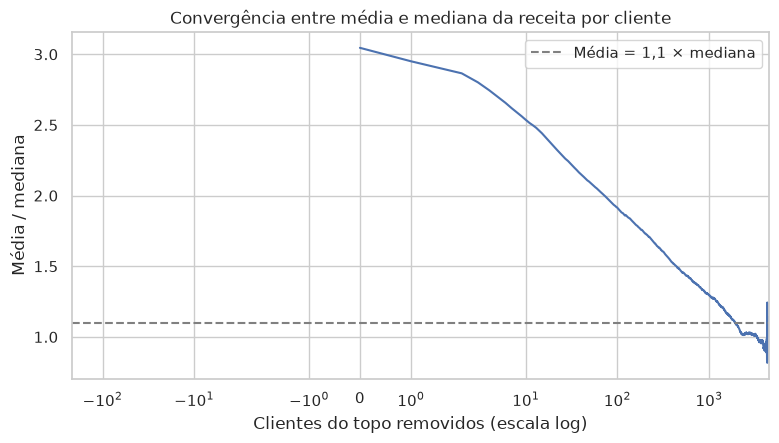

In [26]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(curva["removidos"], curva["razao"], color="C0")
ax.axhline(1.1, color="grey", linestyle="--", label="Média = 1,1 × mediana")
ax.set(xscale="symlog", xlabel="Clientes do topo removidos (escala log)", ylabel="Média / mediana",
       title="Convergência entre média e mediana da receita por cliente")
ax.legend()
plt.show()

**Análise:** a curva cai devagar e de forma contínua: não existe um "degrau" que indique um pequeno grupo de clientes anômalos a remover. Cada faixa de grandes clientes contribui um pouco para afastar a média da mediana. Por isso, para descrever o cliente típico, a solução não é "limpar" os grandes clientes, e sim **usar a mediana** ou **segmentar** (por exemplo, varejo e atacado), como no exemplo bimodal.

## Perguntas para consolidar

**1. Qual "ticket médio" reportar ao gerente de vendas?**

Depende da pergunta que ele quer responder, e nunca deve ser um número sozinho. Para **projetar faturamento**, a média simples (£ 534,40) é a correta, porque multiplicada pelo número de pedidos ela devolve o total. Para descrever o **pedido típico**, a mediana (£ 303,84) ou a média aparada (£ 366,44) são melhores, porque não são puxadas pelos atacadistas. Em qualquer caso, é preciso apresentar junto uma medida de dispersão (o IQR, de £ 152 a £ 496, ou o MAD de £ 162), porque o mesmo ticket médio pode esconder realidades muito diferentes.

**2. A regra de 1,5 × IQR basta para excluir outliers?**

Não. Ela é uma ferramenta de **triagem**: marcou 1.811 pedidos (9,1%), mas boa parte deles são compras legítimas de atacadistas, como mostra a proporção alta de pedidos da Holanda (46%) e da Irlanda (24%) acima do limite. Excluí-los apagaria justamente os melhores clientes. Cada caso marcado precisa de contexto de negócio (quem é o cliente, de que país, se foi cancelado), como fizemos na Aula 03 com os dois pedidos gigantes estornados.

**3. O ano de dados é uma população ou uma amostra?**

Depende da pergunta. Para descrever o que aconteceu **entre dezembro de 2010 e dezembro de 2011**, é a população inteira: não há incerteza amostral, e a média de £ 534,40 é a média verdadeira daquele período. Para **prever o próximo ano**, é uma amostra de um processo que continua, e usá-la assim pressupõe que os padrões (sazonalidade, mix de clientes) se mantêm. É aí que entram as ferramentas de inferência das próximas aulas.

## Conclusão

O valor dos pedidos do Online Retail é um caso extremo de distribuição assimétrica: assimetria de 51, curtose de 4.235, média maior que o terceiro quartil e um último decil que responde por metade do valor esperado. Nessas condições, cada medida responde a uma pergunta diferente. A **média** serve para totais e projeções, a **mediana**, a **média aparada** e o **MAD** descrevem o pedido e a variação típicos, e a **regra do IQR** só faz a triagem dos casos a investigar. O "Para casa" mostrou ainda que a assimetria do preço unitário vem de lançamentos que não são produto e que a distância entre média e mediana da receita por cliente é estrutural: seria preciso remover 44,5% dos clientes para fazê-las convergir.